In [1]:

import pandas as pd

df = pd.read_csv("esg_working_dataset.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Rows and columns: (245, 20)


,ticker,company,sector,industry,esg_rating,esg_score_total,esg_score_environmental,esg_score_social,esg_score_governance,esg_rank_total,data_as_of,market_cap,share_price,price_earnings,dividend_yield,earnings_per_share,ebitda,price_sales,price_book,sec_filings_url
0,MMM,3M Company,Industrials,Industrial Conglomerates,High,35,12.8,14.0,8.4,0.74,2021-03-03,102564405248,222.89,24.31,2.332862,7.92,9.048000e+09,4.390271,11.34,http://www.sec.gov/cgi-bin/browse-edgar?action...
1,ABT,Abbott Laboratories,Health Care,Health Care Equipment,Medium,30,3.0,16.2,10.6,0.56,2021-03-03,217065570304,56.27,22.51,1.908982,0.26,5.744000e+09,3.740480,3.19,http://www.sec.gov/cgi-bin/browse-edgar?action...
2,ABBV,AbbVie Inc.,Health Care,Pharmaceuticals,Medium,29,0.6,17.1,11.3,0.54,2021-03-03,190450155520,108.48,19.41,2.499560,3.29,1.031000e+10,6.291571,26.14,http://www.sec.gov/cgi-bin/browse-edgar?action...
3,ACN,Accenture,Information Technology,IT Consulting & Other Services,Low,11,0.6,5.0,5.8,0.02,2021-03-03,171386028032,150.51,25.47,1.714470,5.44,5.643228e+09,2.604117,10.62,http://www.sec.gov/cgi-bin/browse-edgar?action...
4,ATVI,Activision Blizzard,Communication Services,Interactive Home Entertainment,Low,17,0.2,10.7,6.2,0.12,2021-03-03,74957447168,65.83,31.80,0.431903,1.28,2.704000e+09,10.595120,5.16,http://www.sec.gov/cgi-bin/browse-edgar?action...


In [2]:

# Check the quality of our dataset

print("1. Dataset dimensions:")
print(df.shape)

print("\n2. Missing values in each column:")
print(df.isnull().sum())

print("\n3. Duplicate rows:")
print(df.duplicated().sum())

print("\n4. Duplicate company tickers:")
print(df["ticker"].duplicated().sum())

print("\n5. Data types:")
print(df.dtypes)

print("\n6. ESG score summary:")
print(df[
    ["esg_score_total",
     "esg_score_environmental",
     "esg_score_social",
     "esg_score_governance"]
].describe())


1. Dataset dimensions:
(245, 20)

2. Missing values in each column:
ticker                     0
company                    0
sector                     0
industry                   0
esg_rating                 0
esg_score_total            0
esg_score_environmental    0
esg_score_social           0
esg_score_governance       0
esg_rank_total             0
data_as_of                 0
market_cap                 0
share_price                0
price_earnings             0
dividend_yield             0
earnings_per_share         0
ebitda                     0
price_sales                0
price_book                 0
sec_filings_url            0
dtype: int64

3. Duplicate rows:
0

4. Duplicate company tickers:
0

5. Data types:
ticker                      object
company                     object
sector                      object
industry                    object
esg_rating                  object
esg_score_total              int64
esg_score_environmental    float64
esg_score_social       

In [3]:

# Compare ESG ratings with numerical ESG scores

print("ESG rating counts:")
print(df["esg_rating"].value_counts())

print("\nAverage ESG score by rating:")
print(
    df.groupby("esg_rating")[
        ["esg_score_total",
         "esg_score_environmental",
         "esg_score_social",
         "esg_score_governance"]
    ].mean().round(2)
)

print("\nMinimum and maximum total ESG score by rating:")
print(
    df.groupby("esg_rating")["esg_score_total"]
      .agg(["min", "max", "mean", "count"])
      .round(2)
)


ESG rating counts:
esg_rating
Negligible    154
Severe         63
Medium         12
Low            10
High            6
Name: count, dtype: int64

Average ESG score by rating:
            esg_score_total  esg_score_environmental  esg_score_social  \
esg_rating                                                               
High                  34.00                    14.58             11.22   
Low                   14.50                     1.43              7.40   
Medium                25.83                     6.00             10.94   
Negligible            15.80                     2.90              6.97   
Severe                33.62                    12.05             13.59   

            esg_score_governance  
esg_rating                        
High                        8.30  
Low                         5.76  
Medium                      9.00  
Negligible                  5.90  
Severe                      8.10  

Minimum and maximum total ESG score by rating:
            

In [4]:

# Inspect companies with the highest and lowest total ESG scores

columns_to_show = [
    "company",
    "sector",
    "esg_rating",
    "esg_score_total",
    "esg_score_environmental",
    "esg_score_social",
    "esg_score_governance"
]

print("10 HIGHEST TOTAL ESG SCORES")
display(
    df[columns_to_show]
    .sort_values("esg_score_total", ascending=False)
    .head(10)
)

print("10 LOWEST TOTAL ESG SCORES")
display(
    df[columns_to_show]
    .sort_values("esg_score_total", ascending=True)
    .head(10)
)


10 HIGHEST TOTAL ESG SCORES


,company,sector,esg_rating,esg_score_total,esg_score_environmental,esg_score_social,esg_score_governance
32,APA Corporation,Energy,Severe,39,22.0,9.0,8.0
51,Caterpillar Inc.,Industrials,Severe,39,11.0,20.0,9.0
83,EOG Resources,Energy,Severe,39,20.0,11.0,8.0
98,FMC Corporation,Materials,Severe,39,18.0,14.0,7.0
97,Flowserve Corporation,Industrials,Severe,38,12.0,19.0,8.0
105,General Dynamics,Industrials,Severe,38,10.0,20.0,8.0
102,Freeport-McMoRan Inc.,Materials,Severe,38,19.0,13.0,6.0
12,Albemarle Corporation,Materials,High,37,19.1,8.9,8.7
172,Nucor Corp.,Materials,Severe,37,15.0,14.0,9.0
184,Pioneer Natural Resources,Energy,Severe,37,18.0,10.0,9.0


10 LOWEST TOTAL ESG SCORES


,company,sector,esg_rating,esg_score_total,esg_score_environmental,esg_score_social,esg_score_governance
3,Accenture,Information Technology,Low,11,0.6,5.0,5.8
5,Adobe Inc.,Information Technology,Low,11,0.5,5.7,4.7
10,Air Products & Chemicals,Materials,Low,11,6.1,1.4,3.7
122,Illumina Inc,Health Care,Negligible,11,1.0,4.0,6.0
120,HP Inc.,Information Technology,Negligible,11,0.0,5.0,6.0
196,Robert Half International,Industrials,Negligible,11,0.0,7.0,4.0
201,Seagate Technology,Information Technology,Negligible,11,2.0,4.0,5.0
151,Mettler Toledo,Health Care,Negligible,11,1.0,5.0,6.0
199,Salesforce.com,Information Technology,Negligible,11,0.0,6.0,4.0
230,VF Corporation,Consumer Discretionary,Negligible,11,1.0,6.0,5.0


In [5]:

# Check whether the published risk categories match the scores

print(
    df.groupby("esg_rating")["esg_score_total"]
      .agg(["min", "max", "count"])
      .sort_values("min")
)


            min  max  count
esg_rating                 
Low          11   20     10
Negligible   11   20    154
Medium       21   30     12
Severe       30   39     63
High         31   37      6


,esg_score_total,esg_score_environmental,esg_score_social,esg_score_governance
sector,,,,
Energy,33.44,17.00,9.44,7.33
Utilities,32.73,16.38,10.48,6.03
Materials,27.83,14.85,7.11,5.95
Consumer Staples,26.67,8.98,11.56,6.06
Industrials,26.33,8.14,11.75,6.62
Health Care,22.29,2.09,12.02,8.21
Financials,19.30,1.36,8.60,9.33
Communication Services,18.54,0.52,9.74,8.21
Information Technology,17.37,2.94,8.01,6.30


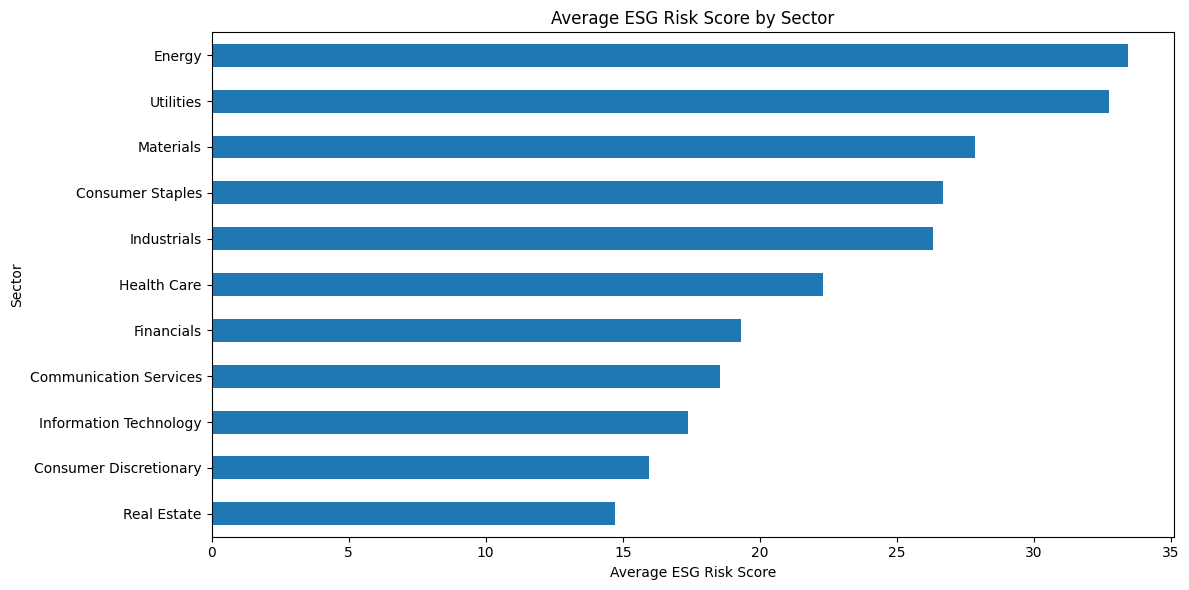

In [6]:

# ESG risk comparison by sector

sector_risk = (
    df.groupby("sector")[
        [
            "esg_score_total",
            "esg_score_environmental",
            "esg_score_social",
            "esg_score_governance"
        ]
    ]
    .mean()
    .round(2)
    .sort_values("esg_score_total", ascending=False)
)

display(sector_risk)

# Visualise average total ESG risk by sector
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sector_risk["esg_score_total"].sort_values().plot(kind="barh")

plt.title("Average ESG Risk Score by Sector")
plt.xlabel("Average ESG Risk Score")
plt.ylabel("Sector")
plt.tight_layout()
plt.show()


,esg_score_total,esg_score_environmental,esg_score_social,esg_score_governance
esg_score_total,1.00,0.76,0.74,0.50
esg_score_environmental,0.76,1.00,0.19,-0.02
esg_score_social,0.74,0.19,1.00,0.54
esg_score_governance,0.50,-0.02,0.54,1.00


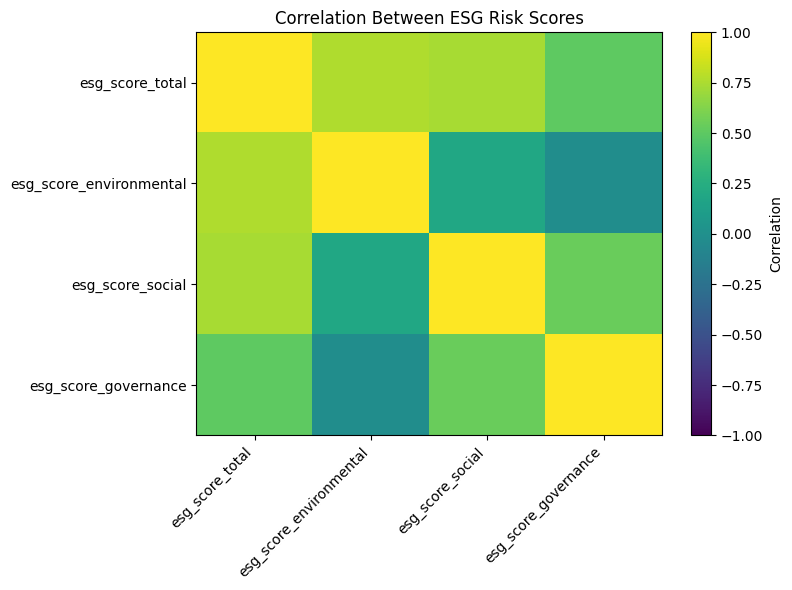

In [7]:

# Correlation between total ESG risk and its pillar scores

score_columns = [
    "esg_score_total",
    "esg_score_environmental",
    "esg_score_social",
    "esg_score_governance"
]

correlation_matrix = df[score_columns].corr().round(2)

display(correlation_matrix)

# Visualise the correlation matrix
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(correlation_matrix, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(score_columns)),
    score_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(score_columns)), score_columns)

plt.title("Correlation Between ESG Risk Scores")
plt.tight_layout()
plt.show()


Correlation with total ESG risk score:


,esg_score_total
price_sales,-0.211
earnings_per_share,-0.171
price_earnings,-0.081
price_book,-0.061
market_cap,-0.018
dividend_yield,0.010
ebitda,0.051


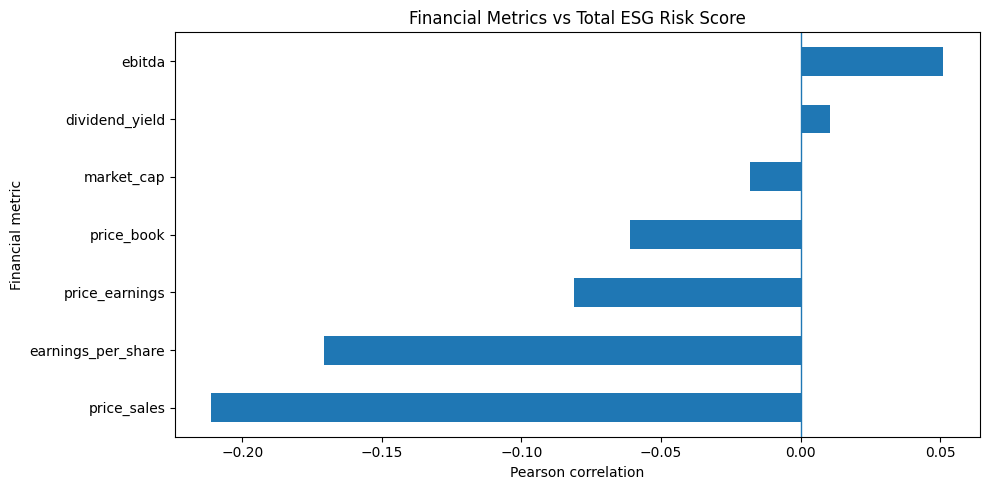

In [8]:

# ESG risk versus financial performance

financial_columns = [
    "market_cap",
    "price_earnings",
    "dividend_yield",
    "earnings_per_share",
    "ebitda",
    "price_sales",
    "price_book"
]

# Calculate correlations with total ESG risk
financial_correlations = (
    df[["esg_score_total"] + financial_columns]
    .corr(numeric_only=True)["esg_score_total"]
    .drop("esg_score_total")
    .sort_values()
)

print("Correlation with total ESG risk score:")
display(financial_correlations.round(3))

# Visualise the relationships
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
financial_correlations.plot(kind="barh")
plt.axvline(0, linewidth=1)
plt.title("Financial Metrics vs Total ESG Risk Score")
plt.xlabel("Pearson correlation")
plt.ylabel("Financial metric")
plt.tight_layout()
plt.show()


In [9]:

from pathlib import Path

output_dir = Path("esg_outputs")
output_dir.mkdir(exist_ok=True)

# Save sector benchmarking
sector_risk.to_csv(
    output_dir / "sector_esg_risk.csv"
)

# Save ESG score correlations
correlation_matrix.to_csv(
    output_dir / "esg_score_correlations.csv"
)

# Save financial correlations
financial_correlations.to_csv(
    output_dir / "esg_financial_correlations.csv"
)

# Save company-level data for Power BI
df.to_csv(
    output_dir / "esg_company_data.csv",
    index=False
)

print("Analysis outputs saved successfully.")
print("Files created:")
for file in output_dir.iterdir():
    print(file.name)


Analysis outputs saved successfully.
Files created:
sector_esg_risk.csv
esg_company_data.csv
esg_score_correlations.csv
esg_financial_correlations.csv


In [10]:

# Create transparent ESG risk-screening flags

def classify_risk(rating):
    if rating == "Severe":
        return "High Priority"
    elif rating == "High":
        return "High Priority"
    elif rating == "Medium":
        return "Review"
    elif rating == "Low":
        return "Monitor"
    elif rating == "Negligible":
        return "Lower Priority"
    else:
        return "Unclassified"

df["risk_screening_flag"] = df["esg_rating"].apply(classify_risk)

print("Risk screening results:")
print(df["risk_screening_flag"].value_counts())

print("\nCompanies requiring high-priority review:")
display(
    df[df["risk_screening_flag"] == "High Priority"][
        ["company", "sector", "esg_rating", "esg_score_total"]
    ].sort_values("esg_score_total", ascending=False)
)

# Save the updated company dataset
df.to_csv("esg_outputs/esg_company_data.csv", index=False)

print("\nUpdated company dataset saved.")


Risk screening results:
risk_screening_flag
Lower Priority    154
High Priority      69
Review             12
Monitor            10
Name: count, dtype: int64

Companies requiring high-priority review:


,company,sector,esg_rating,esg_score_total
32,APA Corporation,Energy,Severe,39
83,EOG Resources,Energy,Severe,39
98,FMC Corporation,Materials,Severe,39
51,Caterpillar Inc.,Industrials,Severe,39
102,Freeport-McMoRan Inc.,Materials,Severe,38
...,...,...,...,...
141,Lilly (Eli) & Co.,Health Care,Severe,31
238,Wells Fargo,Financials,Severe,31
128,Intuitive Surgical Inc.,Health Care,Severe,30
131,Johnson & Johnson,Health Care,Severe,30



Updated company dataset saved.
